# Changeover Guard — tank initialization and CSI training/testing

**Data flow:** the supplied October 29 overhead photograph initializes the colors
of T100, T200 and T400. Training and testing then use **only** the recipe labels
and matching videos in `data/csi-vial-fill-dataset/vial_fill/`. October 29 vial
measurements are not training samples, test samples or fallback data here.

The model first predicts mixture colors from the initialized tank endpoints.
A fixed regularized camera-transfer correction is learned from CSI training
vials and tested on whole recipes excluded from that training fold.

**Kept from earlier work:** ROI review, quality checks, source-time provenance,
recipe-run tracking, operator explanations and explicit missing evidence.
**Changed:** CSI video frames are selected within each labeled fill interval,
not paired by ordinal cycle number. Evaluation holds out entire recipes across
every recording. No test vial or test recipe trains its own expected color.

**No pre-fill subtraction:** only filled-vial color is measured. A pre-fill
inspection may be suggested when a vial is outside tolerance or inconclusive;
that suggestion never changes RGB, Lab or ΔE.

Install with `uv sync --locked --group analysis` and select the `.venv` kernel.
Missing CSI inputs produce a missing-data audit, never October 29 results.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image, display

from changeover_guard.diagnostic_baselines import OCT29_TANK_ROIS
from changeover_guard.diagnostic_workflow import audit_notebooks, run_operator_workflow

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').is_file(), 'Start in the repository or notebooks directory.'
TANK_IMAGE = ROOT / 'data/10_29_26/top_view/images/tank_top_level_10_29_26.jpg'
CSI_DATASET = ROOT / 'data/csi-vial-fill-dataset'
# CSI_DATASET may also point directly to its vial_fill/labels directory.
TANK_ROIS = dict(OCT29_TANK_ROIS)
pd.set_option('display.max_colwidth', 150)
display(pd.Series({
    'tank_initialization_image': str(TANK_IMAGE),
    'training_test_dataset': str(CSI_DATASET),
    'holdout_unit': 'entire recipe, across every CSI recording',
    'pre_fill_subtraction': False,
}))


tank_initialization_image    /workspace/msoe-ai-club-rockwell-automation-nvidia-hackath-cade-rousseau-s-team-f95bb31640/data/10_29_26/top_view/images/tank_top_level_10_29_26.jpg
training_test_dataset                                       /workspace/msoe-ai-club-rockwell-automation-nvidia-hackath-cade-rousseau-s-team-f95bb31640/data/csi-vial-fill-dataset
holdout_unit                                                                                                                            entire recipe, across every CSI recording
pre_fill_subtraction                                                                                                                                                        False
dtype: object

## 1. Review the existing notebook audit

October 29 wall-clock alignment and CSI playback seconds are distinct. The old
approximately 30-second discrepancy is not applied to CSI videos. CSI sampling
uses explicit `start_s` / `end_s` labels and checks decoded frame timing.
The older October 29 analyses remain historical evidence, outside this training
and testing dataset.

In [2]:
audit = audit_notebooks(ROOT)
display(audit[['notebook', 'kept', 'improved_or_not_used']])


,notebook,kept,improved_or_not_used
0,notebooks/operator_diagnostic_system.ipynb,Use the October 29 photograph solely to initialize active-tank colors.,Train/test on CSI whole-recipe holdouts; no October 29 vial fallback or pre-fill subtraction.
1,notebooks/paired_empty_vial_transition_analysis.ipynb,Reuse visual ROI/source review and explicit missing-reference reporting.,No pre-fill subtraction. Use identical holdouts and proxy groups; inspect pre-fill only as operator follow-up.
2,notebooks/transition_analysis.ipynb,"Reuse clock/hash audit, rejected rows, same-recipe runs, camera and model evidence gates.",Hold out the whole evaluated run; never substitute the same run's tail for an independent target.


## 2. Initialize tank colors from your overhead photograph

If the original JPG already exists, it is loaded directly. Otherwise use the
upload control, then rerun Section 3 onward. The image in chat is not automatically
saved to this filesystem. No generated image or guessed RGB is substituted.

Review the explicit yellow liquid ROIs. Physical tank order is T100, T200,
T300 (out of service), T400. Only T100/T200/T400 initialize the optical model.
This photo establishes tank-camera color endpoints, not vial-camera equivalence,
tank concentration or measured liquid levels.

In [3]:
if not TANK_IMAGE.is_file():
    import ipywidgets as widgets

    from changeover_guard.baseline import decode_image

    tank_upload = widgets.FileUpload(accept='.jpg,.jpeg,.png', multiple=False)
    upload_status = widgets.Output()

    def save_tank_upload(change):
        if not tank_upload.value:
            return
        payload = bytes(tank_upload.value[0]['content'])
        with upload_status:
            upload_status.clear_output()
            try:
                image = decode_image(payload)
                TANK_IMAGE.parent.mkdir(parents=True, exist_ok=True)
                TANK_IMAGE.write_bytes(payload)
                print('Tank initialization image saved. Rerun Section 3 onward.')
                print('Dimensions:', image.shape[1], 'x', image.shape[0])
            except ValueError as exc:
                print('Image rejected:', exc)

    tank_upload.observe(save_tank_upload, names='value')
    display(tank_upload, upload_status)
else:
    print('Using tank initialization:', TANK_IMAGE.name)


FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload')

Output()

## 3. Measure the CSI training and testing dataset

The loader discovers `video*_vial_recipes.csv` under the CSI labels folder (and
supports `vial_recipes.csv` for video 5). The matching source recording is
`vial_fill/videos/vial_fill_video_N.mp4`. CSV labels alone do not contain measured
colors; those must come from their matching videos.

Every color sample belongs to its vial's labeled interval. A settled window must
contain consecutive valid samples; gaps, camera movement, clipping and missing
video frames cannot be bridged. No brightness-based empty-vial classifier or
pre-fill measurement is used. Missing/invalid measurements remain in the report.
The ROI contact sheets show the actual representative filled-vial video frames.

status                                                                                                                                                                                   missing_data
tank_initialization_source                                                                                                                  data/10_29_26/top_view/images/tank_top_level_10_29_26.jpg
tank_image_status                                                                                                                                                                       missing_input
training_and_test_dataset                                                                                                                                                  data/csi-vial-fill-dataset
october29_vials_used_for_training_or_testing                                                                                                                                                    False
vials     

""


Missing inputs:
 - /workspace/msoe-ai-club-rockwell-automation-nvidia-hackath-cade-rousseau-s-team-f95bb31640/data/csi-vial-fill-dataset/vial_fill/labels/video*_vial_recipes.csv
 - data/10_29_26/top_view/images/tank_top_level_10_29_26.jpg


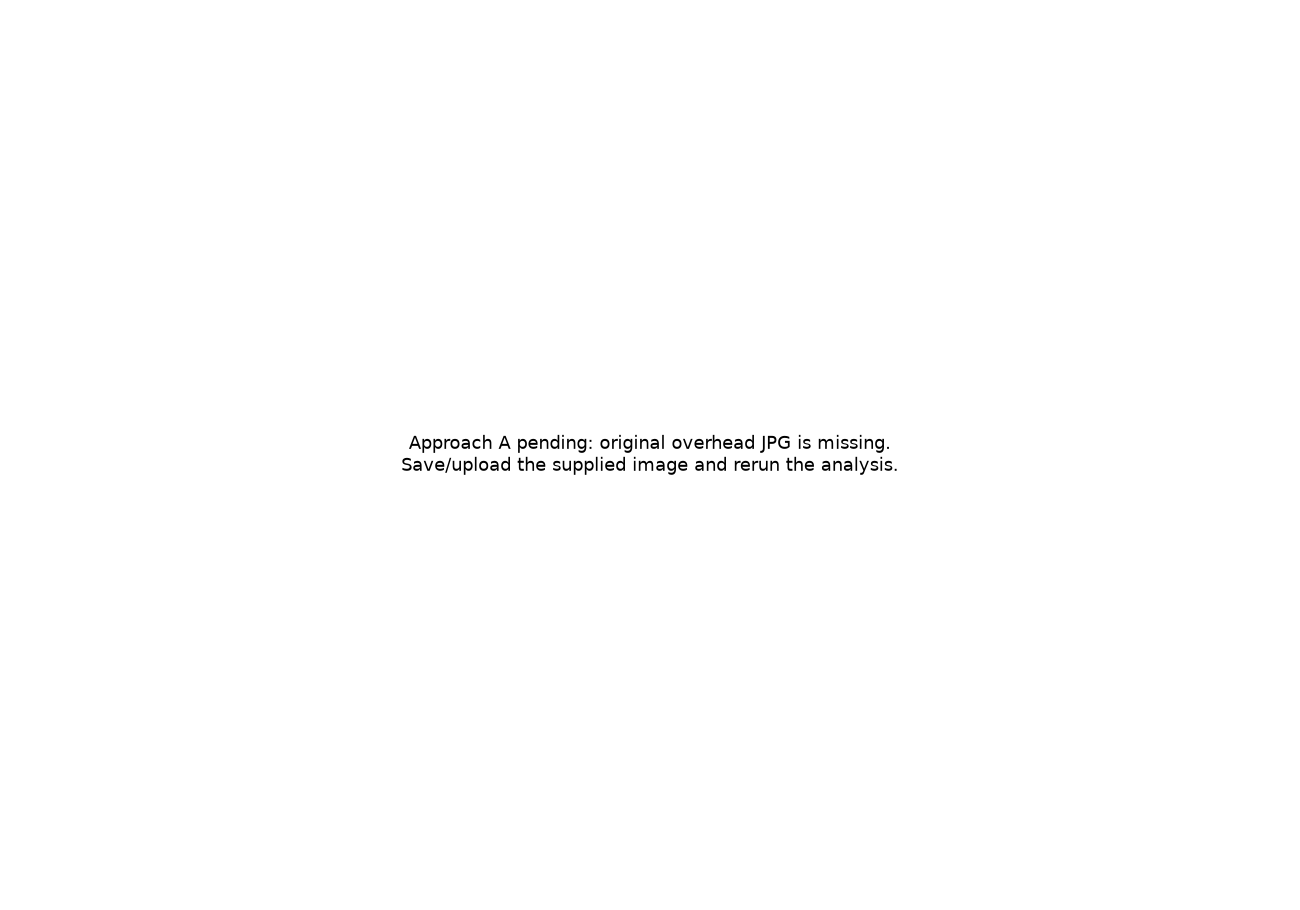

In [4]:
result = run_operator_workflow(
    ROOT, tank_image=TANK_IMAGE, tank_rois=TANK_ROIS, dataset_root=CSI_DATASET
)
OUTPUT = result['output_dir']
measured = result['measurement_result']
measurements = measured['measurements']
display(pd.Series(result['summary']))
display(pd.DataFrame(measured['audit']))
if result['summary']['missing_inputs']:
    print('Missing inputs:')
    for path in result['summary']['missing_inputs']:
        print(' -', path)
display(Image(filename=str(OUTPUT / 'tank_roi_verification.png'), width=950))
for contact in sorted(OUTPUT.glob('csi_vial_roi_*.png')):
    display(Image(filename=str(contact), width=1150))
if not measurements.empty:
    display(measurements[['vial_key', 'recipe_id', 'run_id', 'r', 'g', 'b',
                          'usable', 'quality_flags', 'source_clock_verified']])


## 4. Train on CSI training recipes; test on excluded CSI recipes

**Raw tank model:** linearize the initialized tank RGBs and mix their effective
optical densities by requested recipe fractions. This predicts an unmapped
tank-camera color; camera/path differences are expected.

**Trained tank model:** for each held-out recipe, fit a fixed ridge camera-transfer
correction in linear RGB on usable late-vial proxies of the **other recipes only**.
The correction starts from tank-initialized predictions. Its coefficients,
training identities and training errors are saved for each fold. Identification
requires enough distinct training recipes and a full-rank feature design.

Every vial of a held-out recipe, including its other recordings, is excluded
from training. Different recipe IDs with identical tank fractions are held out
together, even if their total mL differs: this model does not identify a separate
total-volume effect. Out-of-fold test errors are reported separately from training
errors. The ridge setting and primary model are fixed before examining test
outcomes. No test-set threshold tuning is performed; tolerance is ΔE00 < 2.2.

An empirical reference for the held-out recipe would require seeing that recipe
in training. Under this split it therefore stays **unavailable**, rather than
borrowing a test vial as its own target. Late-vial and first-changeover groups
are observational proxies, not independently certified chemical labels.

In [5]:
benchmark = result['benchmark']
display(pd.Series(benchmark['selection']))
print('Training errors (in-sample, not test accuracy):')
display(benchmark['training_metrics'])
print('Held-out CSI test errors:')
display(benchmark['metrics'])
fold_table = pd.DataFrame([{
    'fold_id': fold['fold_id'], 'status': fold['model']['status'],
    'train_recipe_ids': fold['train_recipe_ids'],
    'test_recipe_ids': fold['held_out_recipe_ids'],
    'training_vials': len(fold['train_vial_keys']),
    'test_vials': len(fold['test_vial_keys']),
} for fold in benchmark['folds']])
if not fold_table.empty:
    display(fold_table)
if not benchmark['scores'].empty:
    columns = ['vial_key', 'recipe_id', 'fold_id', 'method', 'partition',
               'trusted', 'reference_available', 'delta_e', 'reference_reason']
    display(benchmark['scores'][[c for c in columns if c in benchmark['scores']]])
    display(Image(filename=str(OUTPUT / 'baseline_comparison.png'), width=1200))
else:
    print('No CSI test scores: resolve missing inputs before interpreting model performance.')


primary_method                                                                            None
status                                                                    missing_measurements
threshold                                                                                  2.2
reason                  CSI measurements unavailable; no October 29 vial fallback is permitted
production_validated                                                                     False
dtype: object

Training errors (in-sample, not test accuracy):


""


Held-out CSI test errors:


,method,partition,scope,eligible_vials,scored_vials,status


No CSI test scores: resolve missing inputs before interpreting model performance.


## 5. Operator diagnostics on held-out CSI predictions

The selected prediction for each vial comes from a model that did not train on
that vial's recipe. Previous-recipe color trajectories use that **same fold's**
model, avoiding mixed camera domains and inconsistent fold calibrations.
Predictions outside the training composition hull remain useful extrapolation
test errors, but cannot trigger a process-cause attribution.

| State | Evidence and response |
|---|---|
| Measurement / sensor reject | Bad/missing color or decoded timing: inspect camera, ROI, exposure and source recording. |
| Carryover suspected | Recipe change plus prior-color trajectory agreement and subsequent decay across consecutive usable vials. Retrospective hypothesis only. |
| Persistent tank / recipe / fill fault suspected | Persistent deviation, supported unrequested signature, verified tank alert or calibrated abnormal fill: investigate the process. |
| In-spec production | Requires independent clean references and camera validation; held-out predictions alone cannot authorize release. |
| Evidence pending | Missing initialization, unidentified model or inconclusive attribution. |

Requested mL is not measured fill. No actual vial-volume or valve-state sensor
evidence is invented. If a vial is outside tolerance or ambiguous, inspect the
same vial's glass/position and consider collecting a pre-fill image on a repeat.
**That is a user suggestion only; no pre-fill color is subtracted.**

In [6]:
operator_report = result['operator_report']
if not operator_report.empty:
    display(operator_report[['vial_key', 'recipe_id', 'diagnostic_label', 'delta_e',
        'color_assessment', 'fill_status', 'production_status', 'explanation',
        'recommended_action', 'prefill_inspection_suggestion']])
    display(Image(filename=str(OUTPUT / 'operator_timeline.png'), width=1250))
    display(HTML((OUTPUT / 'operator_dashboard.html').read_text(encoding='utf-8')))
else:
    print('No CSI inspections available. October 29 production vials have not been substituted.')


No CSI inspections available. October 29 production vials have not been substituted.


## 6. Evidence, artifacts and dataset separation

`training_folds.json` records fitted coefficients and exact training/test
identities. `baseline_scores.csv` contains only held-out CSI predictions.
`baseline_metrics.csv` and the fold records distinguish training errors from test
errors. `csi_trained_model.json` is a separate final all-CSI refit; it is never
used to score held-out test vials. Single-recording recipe holdouts test unseen compositions; they do not
establish generalization to another day or establish chemical purity.

Tank initialization, decoded-frame provenance, quality rejects, missing inputs,
operator explanations and original filled-frame ROIs are exported alongside
the scores. A missing tank photo, CSI labels or matching video blocks the
corresponding stage. There is no automatic October 29 data fallback.
Production and uncertainty remain pending until independently validated.

In [7]:
display(pd.Series(result['summary']))
display(pd.DataFrame({'artifact': sorted(p.name for p in OUTPUT.iterdir() if p.is_file())}))
print('Exports:', OUTPUT.relative_to(ROOT))
assert result['summary']['october29_vials_used_for_training_or_testing'] is False
assert result['summary']['prefill_subtraction_applied'] is False
if not operator_report.empty:
    assert len(operator_report) == len(measurements)
    assert operator_report['vial_key'].is_unique
    assert operator_report['production_status'].eq('PENDING').all()


status                                                                                                                                                                                   missing_data
tank_initialization_source                                                                                                                  data/10_29_26/top_view/images/tank_top_level_10_29_26.jpg
tank_image_status                                                                                                                                                                       missing_input
training_and_test_dataset                                                                                                                                                  data/csi-vial-fill-dataset
october29_vials_used_for_training_or_testing                                                                                                                                                    False
vials     

,artifact
0,baseline_metrics.csv
1,baseline_scores.csv
2,baseline_selection.json
3,csi_measurement_audit.json
4,csi_trained_model.json
5,csi_vial_measurements.csv
6,notebook_audit.csv
7,operator_diagnostic_summary.json
8,operator_root_cause_report.csv
9,operator_root_cause_report.json


Exports: outputs/operator_diagnostics/20261101T204051Z_a509383c
